<h1><strong><span style="font-size: x-large;">ESTUDIO GRAFO STAR WARS.</span></strong></h1>

<p><h3>Construcción grafo Star Wars</h3></p>

In [2]:
import csv
def parse_grafo(ruta):
    g=[]
    with open(ruta , encoding="utf-8") as f:
        lector= csv.reader(f)
        next(lector) 
        for linea in lector:
            relacion=tuple()
            relacion=(linea[0], linea[1], int(linea[2]))
            g.append(relacion)
        return Graph(g, weighted=True)
        

In [3]:
g_ep1= parse_grafo("starwars_ep1_edges_clean.csv")
g_ep2= parse_grafo("starwars_ep2_edges_clean.csv")
g_ep3= parse_grafo("starwars_ep3_edges_clean.csv")
g_ep4= parse_grafo("starwars_ep4_edges_clean.csv")
g_ep5= parse_grafo("starwars_ep5_edges_clean.csv")
g_ep6= parse_grafo("starwars_ep6_edges_clean.csv")
g_ep7= parse_grafo("starwars_ep7_edges_clean.csv")
g_general= parse_grafo("starwars_full_interactions_edges_clean.csv")

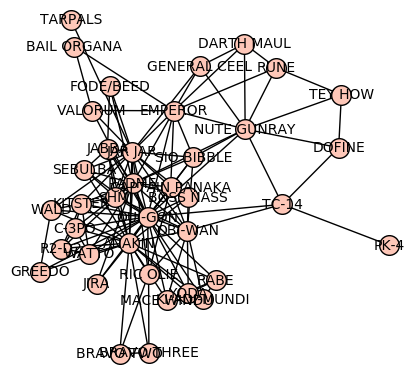

In [4]:
show(g_ep1)

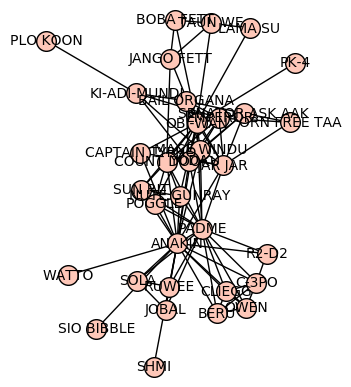

In [5]:
show(g_ep2)

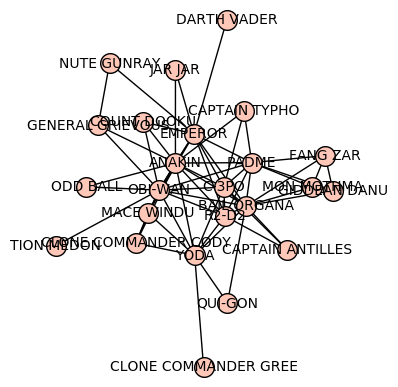

In [6]:
show(g_ep3)

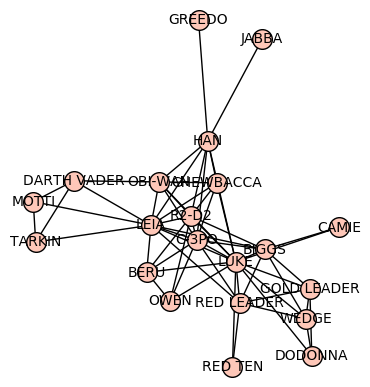

In [8]:
show(g_ep4)

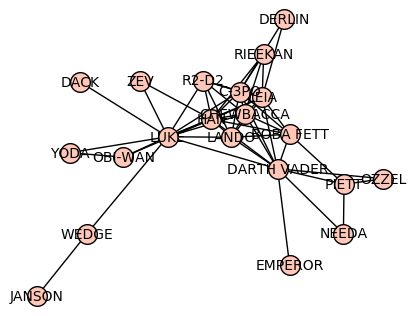

In [9]:
show(g_ep5)

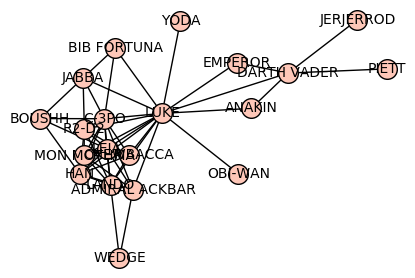

In [10]:
show(g_ep6)

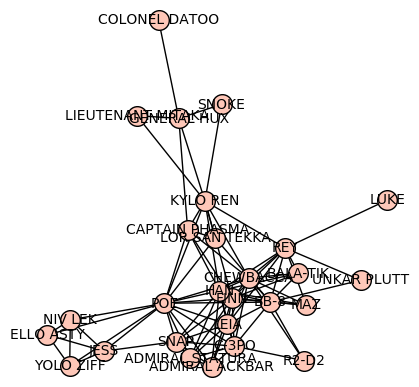

In [11]:
show(g_ep7)

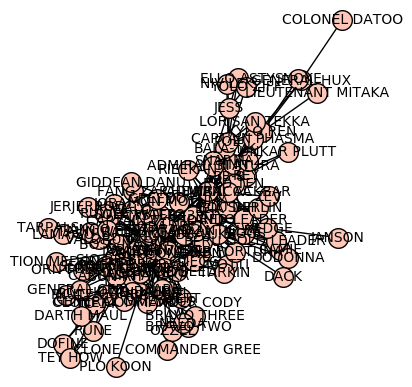

In [12]:
show(g_general)

In [18]:
import networkx as nx

G_ep1 = nx.Graph()
for a, b, peso in g_ep1.edges():
    G_ep1.add_edge(a, b, weight=peso)
    
G_ep2 = nx.Graph()
for a, b, peso in g_ep2.edges():
    G_ep2.add_edge(a, b, weight=peso)
    
G_ep3 = nx.Graph()
for a, b, peso in g_ep3.edges():
    G_ep3.add_edge(a, b, weight=peso)
    
G_ep4 = nx.Graph()
for a, b, peso in g_ep4.edges():
    G_ep4.add_edge(a, b, weight=peso)
    
G_ep5 = nx.Graph()
for a, b, peso in g_ep5.edges():
    G_ep5.add_edge(a, b, weight=peso)
        
G_ep6 = nx.Graph()
for a, b, peso in g_ep6.edges():
    G_ep6.add_edge(a, b, weight=peso)
    
G_ep7 = nx.Graph()
for a, b, peso in g_ep7.edges():
    G_ep7.add_edge(a, b, weight=peso)
    
G_general = nx.Graph()
for a, b, peso in g_general.edges():
    G_general.add_edge(a, b, weight=peso)

<h3>1. Centralidades (el núcleo del trabajo)</h3>
<ul>
  <li><b>Grado (y grado ponderado):</b> con quién habla cada personaje y cuánto. El propio documento avisa de que en redes por escenas se infla en secundarios que aparecen en escenas grupales, así que conviene compararlo con el grado ponderado.</li>
  <li><b>Intermediación (betweenness):</b> quién actúa de puente entre grupos. Aquí encaja la idea del documento de que Palpatine conecta facciones opuestas.</li>
  <li><b>Autovector (eigenvector):</b> quién está conectado con los personajes importantes, no solo con muchos.</li>
  <li><b>Cercanía (closeness):</b> quién llega más rápido a todos los demás.</li>
</ul>

<h3>2. Estructura de la red</h3>
<ul>
  <li>Número de nodos, aristas, densidad y componentes conexas.</li>
  <li><b>Comunidades</b> (por ejemplo Louvain, o el algoritmo de Gephi): ¿salen grupos coherentes con la trama (Naboo, Jedi, Federación de Comercio, Tatooine)?</li>
  <li><b>Camino medio y diámetro</b> (grados de separación).</li>
</ul>

<h3>3. Comparar y concluir</h3>
<ul>
  <li>Hacer un ranking top 5 o top 10 por cada métrica y ver si coinciden. Si el protagonista cambia según la métrica, eso es parte de la discusión.</li>
  <li>Explicar las diferencias por el método de construcción (aristas por escena, con sesgo de "reunión"), como dice el documento.</li>
</ul>

<h2>Metodología</h2>

<h3>Construcción de los grafos</h3>
<p>Los datos proceden del dataset de Evelina Gabasova sobre las interacciones entre personajes de Star Wars. Cada personaje es un nodo y se crea una arista entre dos personajes cuando ambos pronuncian al menos una línea de diálogo en la misma escena. El peso de la arista es el número de escenas en las que coinciden. Se ha construido un grafo no dirigido y ponderado para cada episodio (I a VII) y otro con la red completa de la saga.</p>

<h3>Métricas empleadas</h3>
<table border="1" cellpadding="6" style="border-collapse:collapse">
  <tr><th>Métrica</th><th>Qué mide</th><th>Interpretación en la red</th></tr>
  <tr><td>Grado</td><td>Número de personajes distintos con los que comparte escena</td><td>Cantidad de contactos</td></tr>
  <tr><td>Grado ponderado</td><td>Suma de los pesos de sus aristas</td><td>Número total de escenas compartidas con otros personajes</td></tr>
  <tr><td>Intermediación (betweenness)</td><td>Proporción de caminos mínimos entre pares de personajes que pasan por el nodo</td><td>Personajes que actúan de puente entre grupos</td></tr>
  <tr><td>Autovector (eigenvector)</td><td>Importancia de un nodo en función de la importancia de sus vecinos</td><td>Estar conectado con los personajes importantes, no solo con muchos</td></tr>
  <tr><td>Cercanía (closeness)</td><td>Inverso de la distancia media al resto de nodos</td><td>Rapidez con la que un personaje llega a todos los demás</td></tr>
</table>

<p>La intermediación y la cercanía se calculan sin pesos, de modo que reflejan únicamente la estructura de la red. La razón es que en este grafo un peso alto indica mayor relación (más cercanía), mientras que estos algoritmos interpretan el peso como una distancia. El grado ponderado y el autovector sí utilizan los pesos.</p>

<p>Para describir la estructura global se calculan el número de nodos y aristas, la densidad, las componentes conexas, el camino medio y el diámetro. Las comunidades se detectan con el algoritmo de maximización voraz de la modularidad (greedy modularity), usando los pesos de las aristas.</p>

<h3>Limitaciones del método</h3>
<ul>
  <li><b>Sesgo de reunión:</b> al crear las aristas por escena, si varios personajes hablan en la misma escena todos quedan conectados entre sí. Esto infla el grado de los personajes secundarios que aparecen en escenas grupales, por lo que el grado se contrasta siempre con el grado ponderado.</li>
  <li><b>Menciones indirectas:</b> si un personaje habla de otro que no está presente en la escena, no se crea ninguna arista.</li>
  <li><b>Nombres de personajes:</b> un mismo personaje puede aparecer con nombres distintos según la etapa de la saga (por ejemplo, ANAKIN y DARTH VADER), y se tratan como nodos separados.</li>
</ul>

<h3>Análisis grafo episodio 1</h3>

<p>Grado</p>

In [36]:
grado = dict(G_ep1.degree())
print(sorted(grado.items(), key=lambda x: x[1], reverse=True)[:10])

[('QUI-GON', 26), ('ANAKIN', 23), ('JAR JAR', 18), ('PADME', 18), ('OBI-WAN', 13), ('EMPEROR', 11), ('NUTE GUNRAY', 10), ('CAPTAIN PANAKA', 9), ('KITSTER', 9), ('SHMI', 8)]


<p>Grado ponderado.</p>

In [25]:
grado_pond = dict(G_ep1.degree(weight="weight"))
print(sorted(grado_pond.items(), key=lambda x: x[1], reverse=True)[:10])

[('QUI-GON', 151), ('ANAKIN', 111), ('PADME', 81), ('JAR JAR', 78), ('OBI-WAN', 65), ('R2-D2', 48), ('CAPTAIN PANAKA', 41), ('SHMI', 27), ('NUTE GUNRAY', 24), ('EMPEROR', 23)]


<p>Intermediación (betweenness)</p>

In [26]:
inter = nx.betweenness_centrality(G_ep1)
print(sorted(inter.items(), key=lambda x: x[1], reverse=True)[:10])

[('QUI-GON', 0.3226135226135226), ('ANAKIN', 0.16988362821696154), ('JAR JAR', 0.14583615000281666), ('NUTE GUNRAY', 0.1254313837647171), ('PADME', 0.10342138675472011), ('EMPEROR', 0.10023551690218359), ('TC-14', 0.07318628151961486), ('OBI-WAN', 0.04407145240478574), ('RIC OLIE', 0.02399239065905733), ('VALORUM', 0.015785265785265786)]


<p>Autovector (eigenvector)</p>

In [27]:
auto = nx.eigenvector_centrality(G_ep1, weight="weight")
print(sorted(auto.items(), key=lambda x: x[1], reverse=True)[:10])

[('QUI-GON', 0.5541879173449947), ('ANAKIN', 0.41731372617986107), ('JAR JAR', 0.3515583921104325), ('PADME', 0.3500400944801737), ('OBI-WAN', 0.3267332138652381), ('R2-D2', 0.26477353836686746), ('CAPTAIN PANAKA', 0.18919348729693705), ('SHMI', 0.14969773069443834), ('WATTO', 0.09783112812608905), ('RIC OLIE', 0.064383078867805)]


<p>Cercanía (closeness)</p>

In [28]:
cerc = nx.closeness_centrality(G_ep1)
print(sorted(cerc.items(), key=lambda x: x[1], reverse=True)[:10])

[('QUI-GON', 0.7708333333333334), ('ANAKIN', 0.6491228070175439), ('PADME', 0.6491228070175439), ('JAR JAR', 0.6271186440677966), ('OBI-WAN', 0.5692307692307692), ('EMPEROR', 0.5606060606060606), ('NUTE GUNRAY', 0.5522388059701493), ('CAPTAIN PANAKA', 0.5441176470588235), ('SIO BIBBLE', 0.5285714285714286), ('KITSTER', 0.5211267605633803)]


<p>Comunidades</p>

In [29]:
comunidades = nx.community.greedy_modularity_communities(G_ep1, weight="weight")
print(len(comunidades))
for c in comunidades:
    print(list(c))

11
['VALORUM', 'NUTE GUNRAY', 'BAIL ORGANA', 'EMPEROR', 'DARTH MAUL', 'TEY HOW', 'RUNE', 'DOFINE', 'GENERAL CEEL', 'TC-14', 'SIO BIBBLE', 'PK-4']
['R2-D2', 'KITSTER', 'C-3PO', 'WATTO', 'GREEDO', 'WALD']
['TARPALS', 'JABBA', 'FODE/BEED', 'JAR JAR', 'SEBULBA']
['YODA', 'KI-ADI-MUNDI', 'MACE WINDU', 'RABE']
['BRAVO TWO', 'RIC OLIE', 'BRAVO THREE']
['BOSS NASS', 'CAPTAIN PANAKA']
['JIRA', 'PADME']
['ANAKIN']
['OBI-WAN']
['QUI-GON']
['SHMI']


<p>Estructura: nodos, aristas, densidad y componentes conexas.</p>

In [38]:
print(
    f"nodos: {G_ep1.number_of_nodes()} aristas: {G_ep1.number_of_edges()}"
    f" densidad: {nx.density(G_ep1)}"
)
print(f"componentes conexas: {nx.number_connected_components(G_ep1)}")

nodos: 38 aristas: 135 densidad: 0.19203413940256045
componentes conexas: 1


<p>Camino medio y diámetro.</p>

In [37]:
print(nx.average_shortest_path_length(G_ep1))
print(nx.diameter(G_ep1))

2.1052631578947367
4


<h3>Resultados del episodio I</h3>

<p><b>Estructura.</b> La red tiene 38 personajes y 135 aristas, con una densidad de 0,19. Es un grafo conexo (una sola componente), con un camino medio de 2,11 y un diámetro de 4. Es decir, la red es compacta: desde cualquier personaje se llega a cualquier otro en un máximo de 4 pasos y, en promedio, en poco más de 2.</p>

<p><b>Ranking de centralidades (top 5).</b></p>
<table border="1" cellpadding="6" style="border-collapse:collapse">
  <tr><th>Puesto</th><th>Grado</th><th>Grado ponderado</th><th>Intermediación</th><th>Autovector</th><th>Cercanía</th></tr>
  <tr><td>1</td><td>Qui-Gon (26)</td><td>Qui-Gon (151)</td><td>Qui-Gon (0,323)</td><td>Qui-Gon (0,554)</td><td>Qui-Gon (0,771)</td></tr>
  <tr><td>2</td><td>Anakin (23)</td><td>Anakin (111)</td><td>Anakin (0,170)</td><td>Anakin (0,417)</td><td>Anakin (0,649)</td></tr>
  <tr><td>3</td><td>Jar Jar (18)</td><td>Padmé (81)</td><td>Jar Jar (0,146)</td><td>Jar Jar (0,352)</td><td>Padmé (0,649)</td></tr>
  <tr><td>4</td><td>Padmé (18)</td><td>Jar Jar (78)</td><td>Nute Gunray (0,125)</td><td>Padmé (0,350)</td><td>Jar Jar (0,627)</td></tr>
  <tr><td>5</td><td>Obi-Wan (13)</td><td>Obi-Wan (65)</td><td>Padmé (0,103)</td><td>Obi-Wan (0,327)</td><td>Obi-Wan (0,569)</td></tr>
</table>

<p><b>El protagonista.</b> Qui-Gon encabeza las cinco métricas y Anakin es siempre el segundo, de modo que el resultado no depende de la métrica elegida. Qui-Gon comparte escena con 26 de los otros 37 personajes (un 70 %) y acumula 151 escenas compartidas, lo que concuerda con su papel de guía de la acción en este episodio.</p>

<p><b>Grado frente a grado ponderado.</b> Los dos rankings coinciden en los primeros puestos, pero aparecen diferencias que ilustran el sesgo de reunión. El Emperador (11 contactos, sexto por grado) cae al décimo puesto en grado ponderado (23 escenas), y Kitster (9 contactos) ni siquiera entra en el top 10 ponderado. Son personajes con muchos contactos pero con pocas escenas con cada uno, es decir, conexiones generadas por escenas grupales. En sentido contrario, R2-D2 es sexto por grado ponderado (48) y no está entre los diez primeros por grado: habla con pocos personajes, pero comparte muchas escenas con ellos.</p>

<p><b>Puentes entre grupos.</b> En intermediación aparecen personajes que no destacan en las demás métricas: Nute Gunray (cuarto), el Emperador (sexto), TC-14 (séptimo) y Valorum (décimo). Son personajes del bando de la Federación de Comercio y del Senado que conectan este grupo con el núcleo principal de la historia. En el caso de TC-14, además, es el enlace de un personaje periférico (PK-4) con el resto de la red.</p>

<p><b>El papel del Emperador.</b> En el episodio I el Emperador (Palpatine) ocupa el sexto puesto en intermediación (0,100), por detrás de Qui-Gon, Anakin, Jar Jar, Nute Gunray y Padmé. Por tanto, en este episodio es un puente relevante, pero no el principal. Su papel como conector entre facciones se contrasta en los episodios II y III.</p>

<p><b>Comunidades.</b> El algoritmo detecta 11 comunidades, de las que se pueden interpretar las principales:</p>
<ul>
  <li><b>Federación de Comercio y Senado:</b> Valorum, Nute Gunray, Bail Organa, Emperador, Darth Maul, Tey How, Rune, Dofine, General Ceel, TC-14, Sio Bibble y PK-4.</li>
  <li><b>Tatooine:</b> R2-D2, Kitster, C-3PO, Watto, Greedo y Wald.</li>
  <li><b>Carrera de vainas y gungans:</b> Jabba, Fode/Beed, Sebulba, Jar Jar y Tarpals.</li>
  <li><b>Consejo Jedi:</b> Yoda, Mace Windu y Ki-Adi-Mundi (junto con Rabe).</li>
  <li><b>Pilotos de Naboo:</b> Bravo Two, Bravo Three y Ric Olie.</li>
  <li>Otros grupos pequeños: Boss Nass y Capitán Panaka; Jira y Padmé.</li>
</ul>
<p>Qui-Gon, Anakin, Obi-Wan y Shmi quedan como comunidades de un solo elemento. En el caso de los tres protagonistas, la razón es que sus conexiones se reparten entre muchos grupos distintos, por lo que el algoritmo no puede asignarlos a ninguno. Las comunidades resultantes coinciden en general con los escenarios y facciones de la trama. Sin utilizar los pesos, el algoritmo devuelve una única comunidad con todos los personajes, por lo que se ha empleado la versión ponderada.</p>

<h3>Análisis grafo episodio 2</h3>

<p>Grado</p>

In [42]:
grado = dict(G_ep2.degree())
print(sorted(grado.items(), key=lambda x: x[1], reverse=True)[:10])

[('ANAKIN', 21), ('OBI-WAN', 18), ('PADME', 17), ('COUNT DOOKU', 10), ('JAR JAR', 10), ('MACE WINDU', 10), ('YODA', 10), ('EMPEROR', 9), ('BAIL ORGANA', 7), ('SENATOR ASK AAK', 7)]


<p>Grado ponderado.</p>

In [43]:
grado_pond = dict(G_ep2.degree(weight="weight"))
print(sorted(grado_pond.items(), key=lambda x: x[1], reverse=True)[:10])

[('ANAKIN', 65), ('OBI-WAN', 51), ('PADME', 50), ('MACE WINDU', 24), ('YODA', 24), ('R2-D2', 17), ('COUNT DOOKU', 16), ('C-3PO', 15), ('JAR JAR', 15), ('EMPEROR', 15)]


<p>Intermediación (betweenness)</p>

In [44]:
inter = nx.betweenness_centrality(G_ep2)
print(sorted(inter.items(), key=lambda x: x[1], reverse=True)[:10])

[('ANAKIN', 0.3833822091886608), ('OBI-WAN', 0.3148010927244798), ('PADME', 0.178946725317693), ('KI-ADI-MUNDI', 0.0625), ('JAR JAR', 0.06213037634408602), ('MACE WINDU', 0.06106165340036306), ('YODA', 0.06106165340036306), ('COUNT DOOKU', 0.03698287599497276), ('EMPEROR', 0.028351487222454962), ('BAIL ORGANA', 0.009538646837033935)]


<p>Autovector (eigenvector)</p>

In [45]:
auto = nx.eigenvector_centrality(G_ep2, weight="weight")
print(sorted(auto.items(), key=lambda x: x[1], reverse=True)[:10])

[('ANAKIN', 0.5794937843088441), ('PADME', 0.49033454715273406), ('OBI-WAN', 0.39487909782212144), ('R2-D2', 0.262763938066438), ('C-3PO', 0.17673428498536736), ('MACE WINDU', 0.16788378479100485), ('YODA', 0.16540557715134396), ('COUNT DOOKU', 0.14235135597528606), ('OWEN', 0.14007848040420015), ('JAR JAR', 0.13139560639631453)]


<p>Cercanía (closeness)</p>

In [46]:
cerc = nx.closeness_centrality(G_ep2)
print(sorted(cerc.items(), key=lambda x: x[1], reverse=True)[:10])

[('ANAKIN', 0.7272727272727273), ('OBI-WAN', 0.6808510638297872), ('PADME', 0.6666666666666666), ('MACE WINDU', 0.5925925925925926), ('YODA', 0.5925925925925926), ('COUNT DOOKU', 0.5818181818181818), ('JAR JAR', 0.5818181818181818), ('NUTE GUNRAY', 0.5161290322580645), ('POGGLE', 0.5161290322580645), ('SUN RIT', 0.5161290322580645)]


<p>Comunidades</p>

In [47]:
comunidades = nx.community.greedy_modularity_communities(G_ep2, weight="weight")
print(len(comunidades))
for c in comunidades:
    print(list(c))

8
['ORN FREE TAA', 'KI-ADI-MUNDI', 'BAIL ORGANA', 'EMPEROR', 'YODA', 'MACE WINDU', 'SENATOR ASK AAK', 'PLO KOON', 'JAR JAR']
['OWEN', 'BERU', 'C-3PO', 'CLIEGG']
['JOBAL', 'SOLA', 'RUWEE', 'PADME']
['COUNT DOOKU', 'POGGLE', 'NUTE GUNRAY', 'SUN RIT']
['WATTO', 'ANAKIN', 'SIO BIBBLE', 'SHMI']
['BOBA FETT', 'JANGO FETT', 'TAUN WE', 'LAMA SU']
['OBI-WAN', 'PK-4', 'CAPTAIN TYPHO']
['R2-D2']


<p>Estructura: nodos, aristas, densidad y componentes conexas.</p>

In [48]:
print(
    f"nodos: {G_ep2.number_of_nodes()} aristas: {G_ep2.number_of_edges()}"
    f" densidad: {nx.density(G_ep2)}"
)
print(f"componentes conexas: {nx.number_connected_components(G_ep2)}")

nodos: 33 aristas: 101 densidad: 0.19128787878787878
componentes conexas: 1


<p>Camino medio y diámetro.</p>

In [49]:
print(nx.average_shortest_path_length(G_ep2))
print(nx.diameter(G_ep2))

2.1382575757575757
4


<h3>Interpretación grafo episodio 1</h3>

<h3>Resultados del episodio 2</h3>
